In [4]:
import sys
from pathlib import Path

# Add the backend directory to Python path so we can import agent modules
backend_dir = Path().resolve().parent  # Get parent directory (backend)
if str(backend_dir) not in sys.path:
    sys.path.insert(0, str(backend_dir))

print(f"Python working directory: {Path().resolve()}")
print(f"Added to path: {backend_dir}")
print(f"sys.path[0]: {sys.path[0]}")

Python working directory: D:\llm-projects\projects\study-notes-manager\backend\agent
Added to path: D:\llm-projects\projects\study-notes-manager\backend
sys.path[0]: D:\llm-projects\projects\study-notes-manager\backend


In [18]:
import importlib
import agent.nodes.analyze_node
import agent.nodes.summary_node
import agent.nodes.key_concepts_node
import agent.nodes.quiz_generation_node
import agent.workflow

# Reload the modules to pick up the latest changes
importlib.reload(agent.nodes.analyze_node)
importlib.reload(agent.nodes.summary_node)
importlib.reload(agent.nodes.key_concepts_node)
importlib.reload(agent.nodes.quiz_generation_node)
importlib.reload(agent.workflow)

from agent.workflow import build_workflow

In [6]:
from agent.model.llm import load_llm

In [ ]:
llm = load_llm()

In [19]:
workflow = build_workflow(llm)
app = workflow.compile()

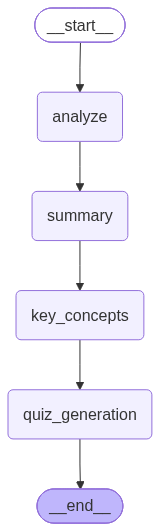

In [12]:
app

In [15]:
initial_state = {
    "note_id": "note_001",
    "note_title": "Introduction to Quantum Computing",
    "note_subject": "Physics",
    "note_content": "Quantum computing leverages quantum mechanics principles like superposition and entanglement to perform computations that are impossible for classical computers.",
    "analysis_result": "",
    "summary_result": "",
    "key_concepts": [],
    "generated_questions": []
}

In [20]:
result = app.invoke(initial_state)

In [21]:
result

{'note_id': 'note_001',
 'note_title': 'Introduction to Quantum Computing',
 'note_subject': 'Physics',
 'note_content': 'Quantum computing leverages quantum mechanics principles like superposition and entanglement to perform computations that are impossible for classical computers.',
 'analysis_result': 'Analysis of the notes: Introduction to Quantum Computing\n\n1) Main Theme\n- The core idea is that quantum computing uses principles of quantum mechanics—specifically superposition and entanglement—to perform computations that are beyond the capabilities of classical computers.\n\n2) Key Points\n- Quantum information is carried by qubits, which behave differently from classical bits.\n- Superposition allows qubits to represent multiple states simultaneously, enabling a form of parallelism.\n- Entanglement creates strong correlations between qubits that enable complex, joint quantum states not possible classically.\n- Quantum operations (gates) manipulate these states, and interference

# Evaluation

In [1]:
from deepeval import evaluate
from deepeval.metrics import FaithfulnessMetric, GEval
from deepeval.test_case import LLMTestCase

ModuleNotFoundError: No module named 'deepeval'

In [ ]:


# 1. Define a mock test case from your Notes Manager
test_case = LLMTestCase(
    input="Generate a 3-question multiple-choice quiz based on these notes.",
    actual_output="""{
        "quizzes": [
          {"question": "What color is chlorophyll?", "options": ["Red", "Green", "Blue"], "answer": "Green"}
        ]
    }""",
    retrieval_context=["Notes: Chlorophyll is a green pigment found in plants that absorbs light for photosynthesis."]
)

# 2. Define the metrics
# Measures if the quiz hallucinated info outside the notes
faithfulness_metric = FaithfulnessMetric(threshold=0.7)

# 3. Execute the evaluation
evaluate([test_case], [faithfulness_metric])
